# ONDO rights supply and valuation
**Aztec Blockchain Group at San Diego State University**  
Franklin Templeton Crypto Research Competition 2026

Offline reproduction of the supplied report, with research cutoff November 8, 2026 Pacific. Historical evidence reads in the source set occurred November 9. This notebook computes from included transfer records and disclosed assumptions; no network access or credentials are needed.

## A Research overview
The report proposes a conditional staged short: ONDO governance and business growth do not establish an automatic commercial cash entitlement for tokenholders. January 2027 scheduled availability creates a supply absorption test. The original wallet investigation asks how inventory has moved, rather than assuming scheduled availability becomes sales.

Foundation commercial ownership gives future value-conversion optionality. Funded tokenholder benefits, stronger demand, or slower delivery can defeat the thesis. These scenarios do not establish intrinsic value, a probability forecast, or an executable trade after costs. See [methodology](../METHODOLOGY.md) and [sources](../data/README.md).

In [1]:
from pathlib import Path
import sys
from decimal import Decimal as D
from IPython.display import display, Markdown
root = Path.cwd() if (Path.cwd() / 'data/assumptions.json').exists() else Path.cwd().parent
if not (root / 'data/assumptions.json').exists():
    raise RuntimeError('Open this notebook from the repository root or notebooks folder')
sys.path.insert(0, str(root / 'scripts'))
import analysis as a
from verify import verify
print(f'Checked {a.verify_files()} evidence files against provenance hashes.')
def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '|' + '|'.join(['---']*len(headers)) + '|']
    lines.extend('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(chr(10).join(lines)))
def show_figure(fig):
    from io import BytesIO
    from IPython.display import Image
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=140)
    display(Image(data=buffer.getvalue()))


Checked 6 evidence files against provenance hashes.


## B Wallet investigation
Only Safe A has official attribution in the supplied source set. The Foundation disclosure identifies its locked ONDO holdings. B and C are **Foundation-linked by inference**, based on A funding and activity. Saved signer observations show no signer overlap with A; funding alone does not prove legal ownership or beneficial control.

The funding table below is recomputed from the supplied selected large-transfer CSV. A-to-B totals 1,548,558,412 ONDO, 100 below the report/memo claim. The export covers transfers of at least 1M ONDO; missing smaller transfers may explain the difference, but the missing record is not supplied. No record is invented to close this gap. This is not a complete funding or balance ledger. B has additional inflows, so its gross payouts cannot be compared only with A-to-B funding. All addresses are Ethereum addresses; the token is ONDO with 18 decimals.

In [2]:
table(['Safe', 'Ethereum address', 'Attribution'],
      [(s, addr, 'Official in source set' if s == 'A' else 'Foundation-linked, inferred') for s, addr in a.WALLETS.items()])
print('ONDO contract:', a.TOKEN)
table(['A funding destination', 'ONDO'], [(s, f'{v:,.6f}') for s,v in a.funding().items()])

| Safe | Ethereum address | Attribution |
|---|---|---|
| A | 0x677fd4ed8ae623f2f625deb2d64f2070e46ca1a1 | Official in source set |
| B | 0x524083970c7a1e62fbaa61d38781f87a4f191fd0 | Foundation-linked, inferred |
| C | 0xea5785e1727de2ba2cefd102cb2dd91e018675e1 | Foundation-linked, inferred |

ONDO contract: 0xfAbA6f8e4a5E8Ab82F62fe7C39859FA577269BE3


| A funding destination | ONDO |
|---|---|
| B | 1,548,558,412.000000 |
| C | 725,000,000.000000 |

## C Transaction analysis
The included CSV is a projection of the supplied transaction export, preserving its core fields and all 203 rows. Unsupported downstream allocation and label columns are excluded. Decimal arithmetic preserves the six-decimal exported amounts.

The source evidence memo reports that all rows matched historical Blockscout records. This run verifies file integrity and reproduces the CSV calculations; the complete historical explorer responses needed to repeat that independent chain audit were not supplied. The source CSV lacks block numbers, log indices, raw integer amounts and a token-contract column. Token filtering is an upstream source assertion, not something this CSV can independently prove.

Four source rows have zero amounts at exported precision. They count as rows in the report but contribute zero to gross payouts. We preserve them rather than change the published sample definition.

In [3]:
rows = a.load_transfers()
summary = a.transfer_summary(rows)
table(['Measure', 'Calculated result'], [(k, f'{v:,}' if isinstance(v, (int,D)) else v) for k,v in summary.items()])
repeated = a.repeated_hash_rows(rows)
table(['Safe', 'Hash', 'Recipient', 'ONDO'], [(r['safe'],r['tx_hash'],r['to'],f"{r['amount_ondo']:,.6f}") for r in repeated])

| Measure | Calculated result |
|---|---|
| rows | 203 |
| unique_hashes | 202 |
| unique_recipients | 166 |
| gross_ondo | 2,357,719,599.756896 |
| zero_amount_rows | 4 |
| safe_B_ondo | 1,668,727,502.067002 |
| safe_C_ondo | 688,992,097.689894 |
| calendar_months | 22 |
| active_months | 20 |
| calendar_average_ondo | 107,169,072.7162225454545454545 |
| active_average_ondo | 117,885,979.9878448 |
| 2025_ondo | 1,359,038,783.067002 |
| 2026_through_october_ondo | 998,680,816.689894 |
| 2025_january_october_ondo | 1,359,038,783.067002 |

| Safe | Hash | Recipient | ONDO |
|---|---|---|---|
| C | 0x5d689f93586164fe2c3323df9f089fdf9bce864ad2c5eb7cf431e7b4a8453bdd | 0x4fca1e37bd07f9c7d0665908dba78a9b92ecbecf | 15,040,950.000000 |
| C | 0x5d689f93586164fe2c3323df9f089fdf9bce864ad2c5eb7cf431e7b4a8453bdd | 0xed6fb27dafee6de3337c81db1626cfa0e6a781cd | 22,594,114.450000 |

One Safe C transaction has two payout rows to different recipients. Deduplicating on transaction hash would lose a valid payout. Without log indices, composite-row uniqueness is a diagnostic rather than a canonical ERC-20 event identifier. Gross transfers may include recycled inventory and do not establish insider sales or net new free float.

## D Monthly distributions
Group by UTC calendar month and Safe, then fill the complete January 2025–October 2026 calendar. The denominator is 22 calendar months, including November and December 2025 without payouts. There are 20 active months; 22 nonempty month/Safe combinations are a different count. Charts use the report's crimson `#A6192E` and navy `#233A50` with gray gridlines.

| UTC month | Safe B (M ONDO) | Safe C (M ONDO) | Combined (M ONDO) |
|---|---|---|---|
| 2025-01 | 536.431 | 0.000 | 536.431 |
| 2025-02 | 176.928 | 0.000 | 176.928 |
| 2025-03 | 5.799 | 0.000 | 5.799 |
| 2025-04 | 118.620 | 0.000 | 118.620 |
| 2025-05 | 238.468 | 0.000 | 238.468 |
| 2025-06 | 42.728 | 0.000 | 42.728 |
| 2025-07 | 96.301 | 0.000 | 96.301 |
| 2025-08 | 34.117 | 0.000 | 34.117 |
| 2025-09 | 87.495 | 0.000 | 87.495 |
| 2025-10 | 22.152 | 0.000 | 22.152 |
| 2025-11 | 0.000 | 0.000 | 0.000 |
| 2025-12 | 0.000 | 0.000 | 0.000 |
| 2026-01 | 122.397 | 0.000 | 122.397 |
| 2026-02 | 24.475 | 0.000 | 24.475 |
| 2026-03 | 87.392 | 0.000 | 87.392 |
| 2026-04 | 75.292 | 63.255 | 138.547 |
| 2026-05 | 0.000 | 148.628 | 148.628 |
| 2026-06 | 0.000 | 63.118 | 63.118 |
| 2026-07 | 0.000 | 75.579 | 75.579 |
| 2026-08 | 0.000 | 143.331 | 143.331 |
| 2026-09 | 0.000 | 129.876 | 129.876 |
| 2026-10 | 0.133 | 65.206 | 65.339 |

Calendar average: 107.169073M ONDO
Active-month average: 117.885980M ONDO
Jan–Oct 2025: 1359.038783M
Jan–Oct 2026: 998.680817M


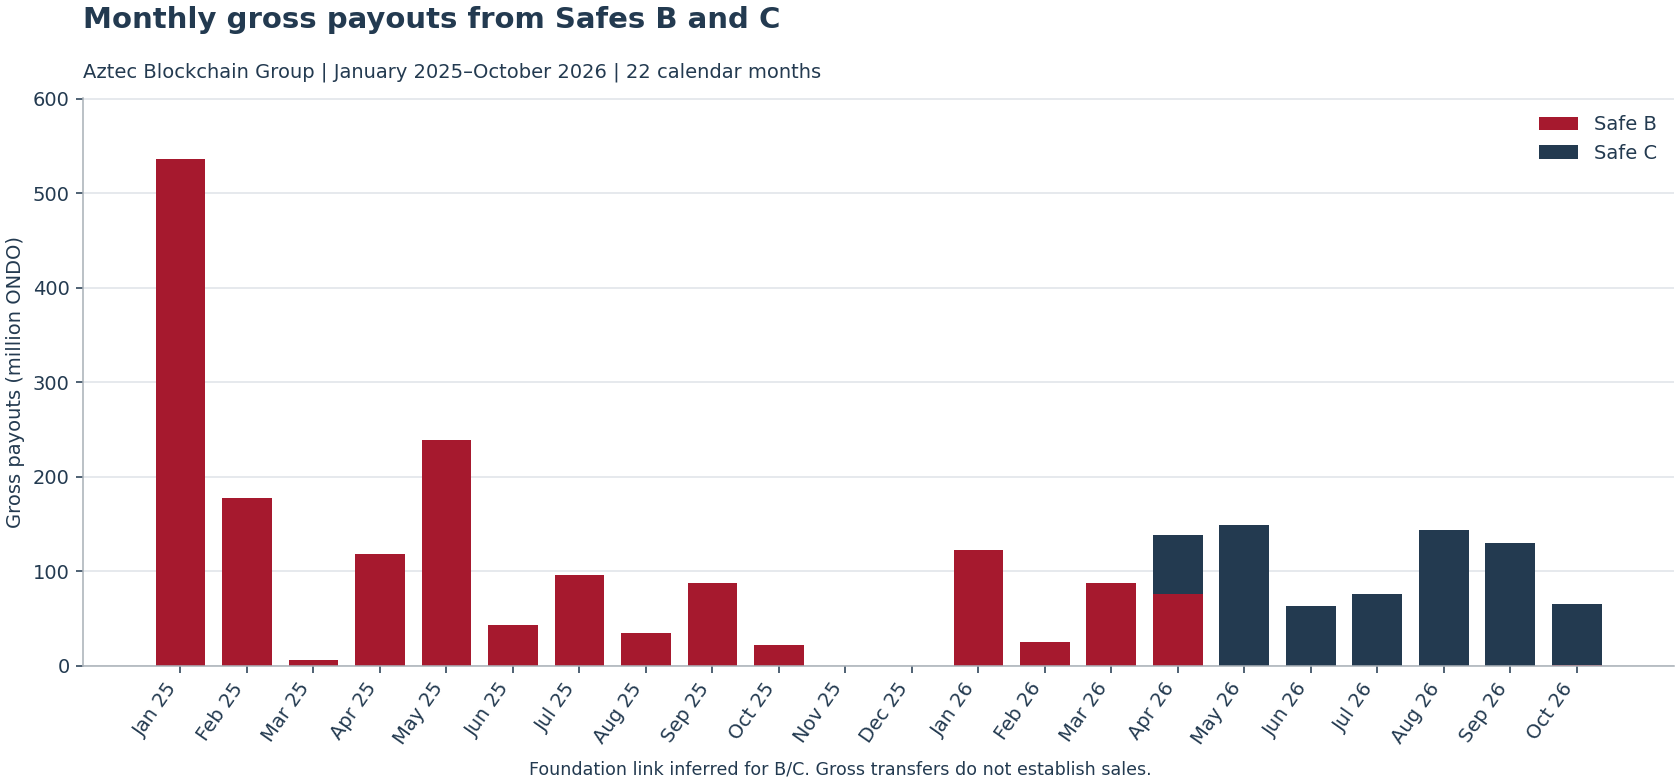

In [4]:
months = a.monthly_totals(rows)
table(['UTC month', 'Safe B (M ONDO)', 'Safe C (M ONDO)', 'Combined (M ONDO)'],
      [(r['month'],*(f'{r[k]/1000000:,.3f}' for k in ('B','C','combined'))) for r in months])
print(f"Calendar average: {summary['calendar_average_ondo']/1000000:.6f}M ONDO")
print(f"Active-month average: {summary['active_average_ondo']/1000000:.6f}M ONDO")
print(f"Jan–Oct 2025: {summary['2025_january_october_ondo']/1000000:.6f}M")
print(f"Jan–Oct 2026: {summary['2026_through_october_ondo']/1000000:.6f}M")
fig = a.monthly_figure(months)
show_figure(fig)
a.style().close(fig)

Comparable January–October payouts declined in 2026. The observed record does not support an acceleration claim. Do not extrapolate the calendar average into a January realization forecast.

## E January 2027 scheduled availability
The working **five-step schedule interpretation** is implemented as:

1. Start with the published category allocations, not rounded billions.
2. Remove the 24% initial ecosystem release, leaving 76% scheduled.
3. Divide that ecosystem remainder among five annual steps.
4. Divide protocol development and private-sale allocations by five.
5. Add the three components for one working annual tranche.

The proposal lists steps 12, 24, 36, 48 and 60 months after launch. Alternative wording describes at least 12 months locked and release over the following four years. Dividing development/private by four gives a separate interpretation, not an additional release. Investor documentation also describes a one-year lock plus 48-month release. Matching aggregate supply jumps does not authenticate beneficiary-specific terms.

Use the January 2027 release window: January 17/18 exact epoch and timezone remain unresolved. Scheduled transferability, wallet delivery, vendor circulation and executed sales are distinct observations.

In [5]:
u = a.unlock()
table(['Component', 'Calculated ONDO'], [(k,f'{v:,.2f}') for k,v in u.items() if not k.startswith('pct')])
print(f"Working tranche / reference circulation: {u['pct_reference_circulation']:.4f}%")
print(f"Working tranche / total supply: {u['pct_total_supply']:.4f}%")

| Component | Calculated ONDO |
|---|---|
| ecosystem | 792,052,170.84 |
| protocol | 660,000,000.00 |
| private | 258,049,208.80 |
| total | 1,710,101,379.64 |
| alternative_total | 1,939,613,681.84 |

Working tranche / reference circulation: 35.1198%
Working tranche / total supply: 17.1010%


## F Valuation scenarios
Inputs are explicit in `data/assumptions.json`. The later package-reported market snapshot lacks its original CoinGecko API body. It remains a qualified working reference. The older archived response is a different observation and cannot authenticate it.

Use capitalization divided by circulation consistently, rather than mix the reported quote with inconsistent capitalization. For realization fraction $r$ and capitalization change $g$:

$$P(r,g)=\frac{C_0(1+g)}{S_0+U r}$$

Here $U$ is calculated from allocations above. No historical gross payouts are added as a second tranche. Realization means an analyst-assumed increase in modeled circulating supply, not a measured sale fraction.

| Working input | Value |
|---|---|
| reference_cap_usd | 1695052960 |
| reference_circulating_ondo | 4869330647 |
| reported_quote_usd | 0.348318 |
| reported_snapshot_time | 2026-11-08T23:36:53-08:00 |

| Reconciliation | Calculated value |
|---|---|
| cap_implied_price | 0.348108001 |
| quote_times_supply | 1,696,075,512.301746000 |
| quote_cap_gap_pct | 0.060325685 |
| post_full_release_circulation | 6,579,432,026.640000000 |
| cap_to_preserve_reference_price | 2,290,352,933.569214417 |
| required_holder_cashflow_at_20x | 84,752,648.000000000 |
| required_source_earnings_at_40pct_capture_20x | 211,881,620.000000000 |

| Release realization | USD / ONDO | Change from cap-implied reference |
|---|---|---|
| 0% | $0.3481 | +0.0% |
| 50% | $0.2961 | -14.9% |
| 100% | $0.2576 | -26.0% |

| Cap change | No release | 50% release | 100% release |
|---|---|---|---|
| -25% | $0.2611 | $0.2221 | $0.1932 |
| +0% | $0.3481 | $0.2961 | $0.2576 |
| +25% | $0.4351 | $0.3701 | $0.3220 |
| +50% | $0.5222 | $0.4442 | $0.3864 |
| +100% | $0.6962 | $0.5922 | $0.5153 |

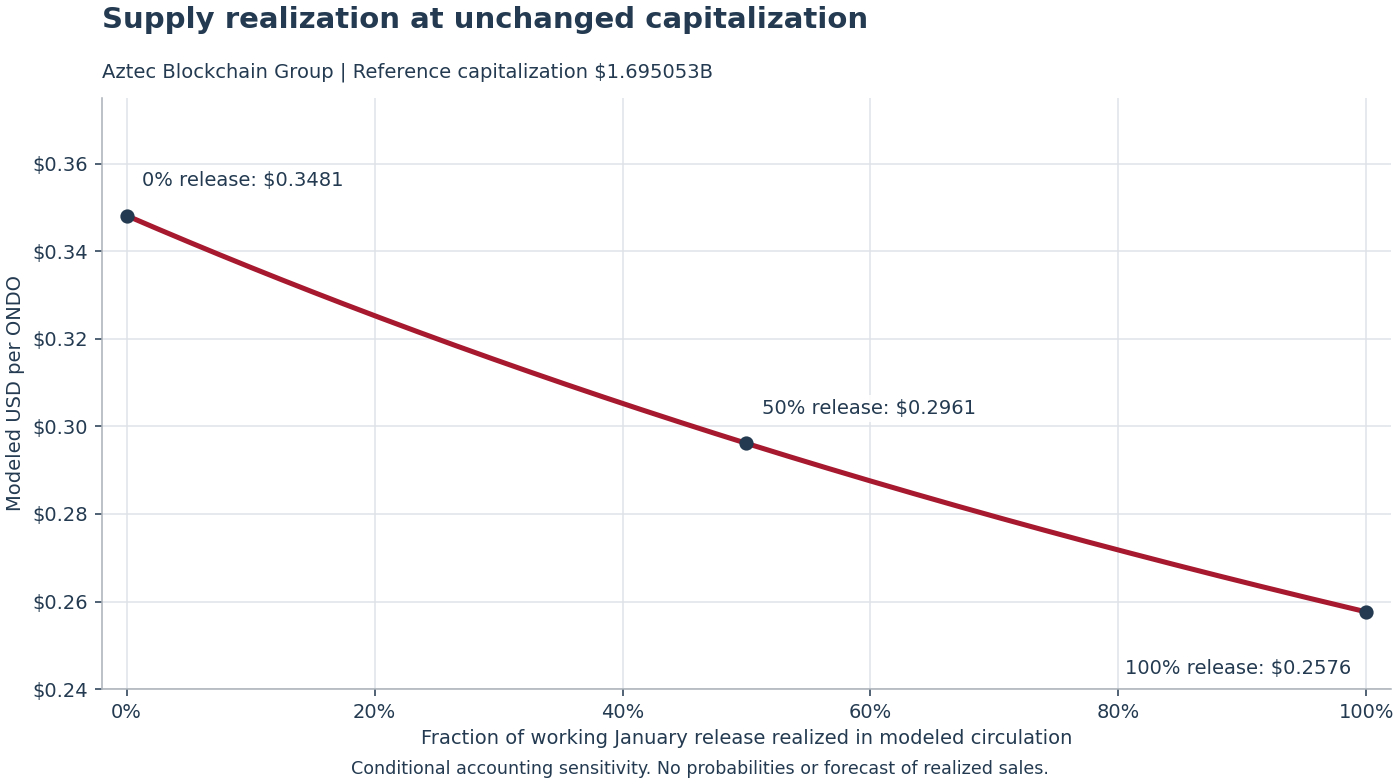

In [6]:
inputs = a.assumptions()
table(['Working input', 'Value'], [(k,inputs[k]) for k in ('reference_cap_usd','reference_circulating_ondo','reported_quote_usd','reported_snapshot_time')])
recon = a.snapshot_reconciliation()
table(['Reconciliation', 'Calculated value'], [(k,f'{v:,.9f}') for k,v in recon.items()])
table(['Release realization', 'USD / ONDO', 'Change from cap-implied reference'],
      [(f'{D(r):.0%}',f'${a.price(r):.4f}',f'{(a.price(r)/a.price(0)-1)*100:+.1f}%') for r in inputs['release_realizations']])
table(['Cap change', 'No release', '50% release', '100% release'],
      [(f"{D(row['capitalization_change']):+.0%}",*(f'${row[r]:.4f}' for r in inputs['release_realizations'])) for row in a.sensitivity()])
fig = a.sensitivity_figure()
show_figure(fig)
a.style().close(fig)

The 201-point curve evaluates the formula directly. Constant capitalization is an assumption, not a forced market outcome. Maintaining the reference price after full realization requires 35.12% higher capitalization; the difference is not a dollar-for-dollar cash inflow requirement. Reverse cash-flow calculations assume a holder-cash-flow multiple and a defined net source earnings capture, not a corporate revenue multiple.

## G Historical counterevidence
Recompute the report's anniversary convention from saved public Coinbase candles: January 18 event date, start at day −1 close, end at day +30 close (31 close-to-close intervals). UTC candle dates are not exact unlock epochs. Simple ONDO-minus-BTC return subtraction is neither beta-adjusted alpha nor causal identification. Two events do not establish a reliable unlock crash.

In [7]:
history = a.historical_counterevidence()
table(['Year','Start UTC close','End UTC close','ONDO','BTC','ONDO minus BTC (pp)'],
      [(r['year'],r['start_close_date_utc'],r['end_close_date_utc'],f"{r['ONDO']:.3f}%",f"{r['BTC']:.3f}%",f"{r['ONDO_minus_BTC_pp']:+.3f}") for r in history])

| Year | Start UTC close | End UTC close | ONDO | BTC | ONDO minus BTC (pp) |
|---|---|---|---|---|---|
| 2025 | 2025-01-17 | 2025-02-17 | -5.986% | -7.997% | +2.011 |
| 2026 | 2026-01-17 | 2026-02-17 | -28.721% | -29.065% | +0.344 |

## H Verification and reproducible exports
Regression targets live only in the verification code. Calculations never load expected totals. Checks cover source integrity, sample counts, gross/annual/Safe totals, zero months, duplicate-hash treatment, funding, unlock alternatives, all 15 Appendix B prices and historical counterevidence. This verifies arithmetic and internal consistency, not missing upstream chain records or scenario economics.

In [8]:
checks = verify()
result = a.export_results(rows)
print(f'PASS: {len(checks)} automated checks')
print('Saved monthly CSV, calculated JSON, and PNG/SVG figures using the same functions displayed above.')

PASS: 32 automated checks
Saved monthly CSV, calculated JSON, and PNG/SVG figures using the same functions displayed above.


## I Evidence limits
- The later market snapshot's original API body is absent; use the cap-implied reference with its qualification.
- B/C ownership remains inferred. Selected A funding rows do not prove complete balance reconciliation.
- Full historical explorer responses and canonical transfer event identifiers are missing; source-reported chain matching cannot be independently rerun offline.
- Recipient histories and dated label dictionaries required for exchange-routing allocation are missing. No downstream estimates or insider-selling claims are included.
- Beneficiary-level vesting terms and exact release timestamp remain unresolved.
- Neither gross payouts nor conditional prices identify economic free float, execution costs, probabilities or a fair-value target.

Sources and redistribution review are in [data/README.md](../data/README.md); local verification details are in [VERIFICATION.md](../VERIFICATION.md). The report and archives are intentionally not distributed with this repository.